<a href="https://colab.research.google.com/github/erikarosado/ia-y-aprendizaje-automatico/blob/main/MNA_IAyAA_Actividad_Clasificacio%CC%81n_y_rotacion_de_personal_sept2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

Actividad de Semana 3

### **Rotación de Personal - IBM**

* **Nombre:**Erika Rosado Treviño

* **matrícula:**A00846135

------------

* #### **En esta actividad puedes apoyarte en uno o varios Modelos de Lenguaje de Gran Tamaño, LLM por sus siglas en inglés (Large Language Model). Indica claramente cuál o cuáles utilizaste.**

* #### **La siguiente actividad se basa en los datos del archivo "WA_Fn-UseC_-HR-Employee-Attrition.csv" que se encuentra en la siguiente liga de Kaggle, llamada "IBM HR Analytics Employee Attrition & Performance".**

* #### **Los datos los proporcionó IBM y aunque comentaron que por cuestiones de privacidad los datos son sintéticos, los generaron con base a su experiencia. Estos datos en general son referencia cuando se habla en Estadística o Aprendizaje Automático sobre el tema de rotación de personal.**

**El archivo contiene 1470 registros:**

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


# **Ejercicio 1:**

#### **Incluye una breve introducción sobre lo que se entiende por el problema de rotación de personal en las organizaciones (employee attrition problem).**


La rotación de personal se refiere a la salida de empleados de una organización, especialmente cuando deciden renunciar voluntariamente. Es importante para las empresas evitar la rotación de personal ya que esto tiene un impacto para la organización, deben contratar a otra persona e invertir tiempo en su capacitación.

In [1]:
# Agrega aquí todas las librerías adicionales o paquetes que consideres necesarias:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report



* #### **Descarga el archivo de datos de la página de Kaggle.**

* #### **Cargamos el archivo como un DataFrame de Pandas y hacemos uso del método “describe” con el argumento include= “all” para desplegar información de todas las variables, numéricas y categóricas.**

In [3]:
path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
data = pd.read_csv(path)

print("Tamaño del DataFrame:", data.shape)
data.describe(include = 'all').T


Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


# **Ejercicio 2:**

**a) Realiza los análisis descriptivos y/o gráficos que creas adecuados para identificar 4 factores que se deben eliminar desde un inicio.**

**Al nuevo DataFrame sin las variables indicadas, llamarlo df.**



In [5]:
# a) Variables un valor:
print(data.nunique().sort_values().head(3), "\n")
print("Valores distintos de EmployeeNumber:", data['EmployeeNumber'].nunique(), "\n")

df = data.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])

# ++++++++++ Termina sección para agregar código +++++++++++++++++++++++++++


# Verifiquemos de qué tamaño queda el nuevo DataFrame:
print("Tamaño del nuevo DataFrame:", df.shape)

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64 

Valores distintos de EmployeeNumber: 1470 

Tamaño del nuevo DataFrame: (1470, 31)


**b) Con base a tu análisis anterior, indica cuáles fueron estas 4 variables y la justificación de por qué se pueden eliminar.**

Las 4 variables que se pueden eliminar desde un inicio son EmployeeCount, Over18, StandardHours y EmployeeNumber. Las tres primeras variables mencionadas se eliminan por ser constantes, es decir, por tener varianza cero y la última por ser un identificador con valores únicos. De esta manera, el DataFrame pasa de 35 a 31 columnas.
Cuando una variable se mantiene constante no suele aportar información relevante, ni tiene valor predictivo. Mientras que los identificadores no aportan características sobre los empleados.



# **Ejercicio 3:**

#### **Una vez eliminadas las variables no deseadas, clasifiquemos las restantes como se indica a continuación y en base a la información dada en la plataforma de Kaggle.**

#### **El número entre corcheas indica el número de variables de dicho tipo y el  número entre paréntesis redondos indica el número de niveles.**

* **Variables numéricas [14]:**

   * NumCompaniesWorked

   * TrainingTimesLastYear

   * Age

   * DailyRate

   * DistanceFromHome

   * HourlyRate

   * MonthlyIncome

   * MonthlyRate

   * PercentSalaryHike

   * TotalWorkingYears

   * YearsAtCompany

   * YearsInCurrentRole

   * YearsSinceLastPromotion

   * YearsWithCurrManager

* **Variables ordinales [9]:**

   * Education (5)

   * EnvironmentSatisfaction (4)

   * JobInvolvement (4)

   * JobLevel (5)

   * JobSatisfaction (4)

   * PerformanceRating (2)

   * RelationshipSatisfaction (4)

   * StockOptionLevel (4)

   * WorkLifeBalance (4)

* **Variables binarias [3]:**

   * Attrition (variable de salida)

   * Gender

   * OverTime

* **Variables nominales [5]:**

   * BusinessTravel (3)

   * Department (3)

   * EducationField (6)

   * JobRole (9)

   * MaritalStatus (3)

**Indpendientemente de los factores que al final el modelo identifique como los factores más importantes a considerar en este problema de rotación de personal ¿qué preocupaciones éticas o legales podrían generarse, si algunos de estos factores más importantes a considerar para tomar decisiones sobre los empleados fueran la edad (Age), el género (Gender) o el estado civil (Marital Status)?**



Aunque el modelo vea que la edad, el género o el estado civil ayudan a adivinar quién va a renunciar, no es conveniente usarlos para la toma de decisiones. Primero, porque la ley no permite tratar distinto a alguien por esas razones; la empresa podría sufrir consecuencias legales por discriminación. Segundo, porque no es justo: el modelo aprende de datos del pasado que pueden traer desigualdades escondidas, y que dos cosas aparezcan juntas no quiere decir que una cause la otra. Además, se corre el riesgo de formar sesgos y dejar de apostar por personas con cierto perfil. Es conveniente dejar esas variables fuera del modelo para evitar problemas éticos y legales y evitar que el modelo tome un comportamiento sesgado.



# **Ejercicio 4:**

**a) Aunque este problema como está planteado es un problema de clasificación binaria, ¿qué otros enfoques analíticos podrían plantearse y modelarse a partir de este problema? Menciona al menos dos más.**



Una opción sería el análisis de supervivencia. En lugar de hacer la pregunta sobre si se va o se queda un empleado, se preguntaría cuánto tiempo falta para que se vaya. Usando variables como YearsAtCompany o YearsSinceLastPromotion, es posible armar curvas de supervivencia (Kaplan-Meier) o modelos de riesgo (Cox) para saber en qué momento es más probable que alguien renuncie.
Otra alternativa sería el agrupamiento o clustering. Es un enfoque no supervisado que no utiliza la variable Attrition. En este caso se agrupan empleados con perfiles similares entre sí, como con el caso con K-means, y después se revisa qué grupos tienen más rotación, lo que ayuda a descubrir tipos de empleados en los que no se había pensado.


### **Para esta actividad usaremos una partición en Train, Val y Test, con los porcentajes que se indican a continuación.**

In [6]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)

Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


# **Ejercicio 5:**


**a) Aplica la transformación LabelEncoder() de Sklearn a la variable“Attrition”, tomando en cuenta los siguientes puntos:**

* **Las nuevas variables deberán llamarse ahora: ytrainT, yvalT, ytestT.**

* **Al aplicar la transformación LabelEncoder deberás evitar el filtrado de información (data-leakage).**


In [7]:
# a) LabelEncoder ajustado con Train, aplicar a Val y Test

le = LabelEncoder()
ytrainT = pd.DataFrame(le.fit_transform(np.ravel(ytrain)), columns=['Attrition'], index=ytrain.index)
yvalT = pd.DataFrame(le.transform(np.ravel(yval)), columns=['Attrition'], index=yval.index)
ytestT = pd.DataFrame(le.transform(np.ravel(ytest)), columns=['Attrition'], index=ytest.index)


print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])

Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 Attrition
0    0.838678
1    0.161322
Name: count, dtype: float64


#### Además, responde las siguientes preguntas:

**b) Con base a la documentación actual de Sklearn, ¿a qué tipo de variables se recomienda aplicar la transformación LabelEncoder?**

**c) Con base al contexto del problema, ¿qué significan los valores 0 (NO) y 1 (YES) de la variable de salida Attrition?**

**d) Con base a la información obtenida y considerando la métrica de la exactitud (accuracy) ¿cuál será el valor del umbral del modelo base o ingenuo (baseline, naive) a superar para evitar tener un modelo subentrenado una vez que empecemos a generarlos?**

**e) Indica si el desbalanceo de clases obtenido puede ya considerarse como un problema, y de considerarlo así, qué otra métrica o métricas podrían ser más adecuadas que la exactitud (accuracy).**




b) LabelEncoder se recomienda solo para la variable objetivo (y), no para las de entrada.
c) El valor 0 (NO) significa que el empleado se queda; el valor 1 (YES) significa que se va de la empresa. La clase 1 es la de interés en este caso.
d) El umbral es la exactitud del modelo que siempre predice la clase mayoritaria: 0.838678 (≈83.87%). Si el modelo no supera ese valor, esto quiere decir que está subentrenado.
e) Sí se consideraría como un problema porque un modelo puede tener alta exactitud ignorando a quienes se van. Son mejores alternativas el recall, la precisión, el F1-score, la matriz de confusión y la balanced accuracy.



# **Ejercicio 6:**


#### **Incluye a continuación un análisis gáfico y descriptivo que consideres adecuado.**

  * **a) El análisis debe ser suficiente para que te ayude a tomar las decisiones sobre qué transformaciones aplicar a cada variable antes de entrenar los modelos.**

  * **b) Además, para obtener mayor información sobre la relación entre variables, incluye un gráfico de barras de frecuencias ordenadas de mayor a menor, de la variable "Age", únicamente para los casos de empleados que ya no están en la compañía (Attrition=Yes).**

  * **c) Incluye también un gráfico de barras ordenado de la relación entre Education y Attrition=Yes. Muestra además en el gráfico las etiquetas asociadas a Education en lugar de los números, como se indica en la página de Kaggle.**

  * **d) [Opcional] Incluye algún otro gráfico o gráficos que consideres aporta información para el análisis y entendimiento del problema. Si no encuentras algún otro gráfico de interés, deberas indicarlo.**

  * **e) Para la empresa de IBM ¿qué es más costoso? ¿clasificar erróneamente a un empleado que sí renunciará, o por el contrario, generar una falsa alarma?**


Datos faltantes: 0 

Sesgo de las variables numéricas:
YearsSinceLastPromotion    2.04
YearsAtCompany             1.81
MonthlyIncome              1.39
TotalWorkingYears          1.16
NumCompaniesWorked         1.08
DistanceFromHome           0.89
YearsInCurrentRole         0.87
PercentSalaryHike          0.84
YearsWithCurrManager       0.75
TrainingTimesLastYear      0.51
Age                        0.43
MonthlyRate                0.04
DailyRate                 -0.02
HourlyRate                -0.07
dtype: float64


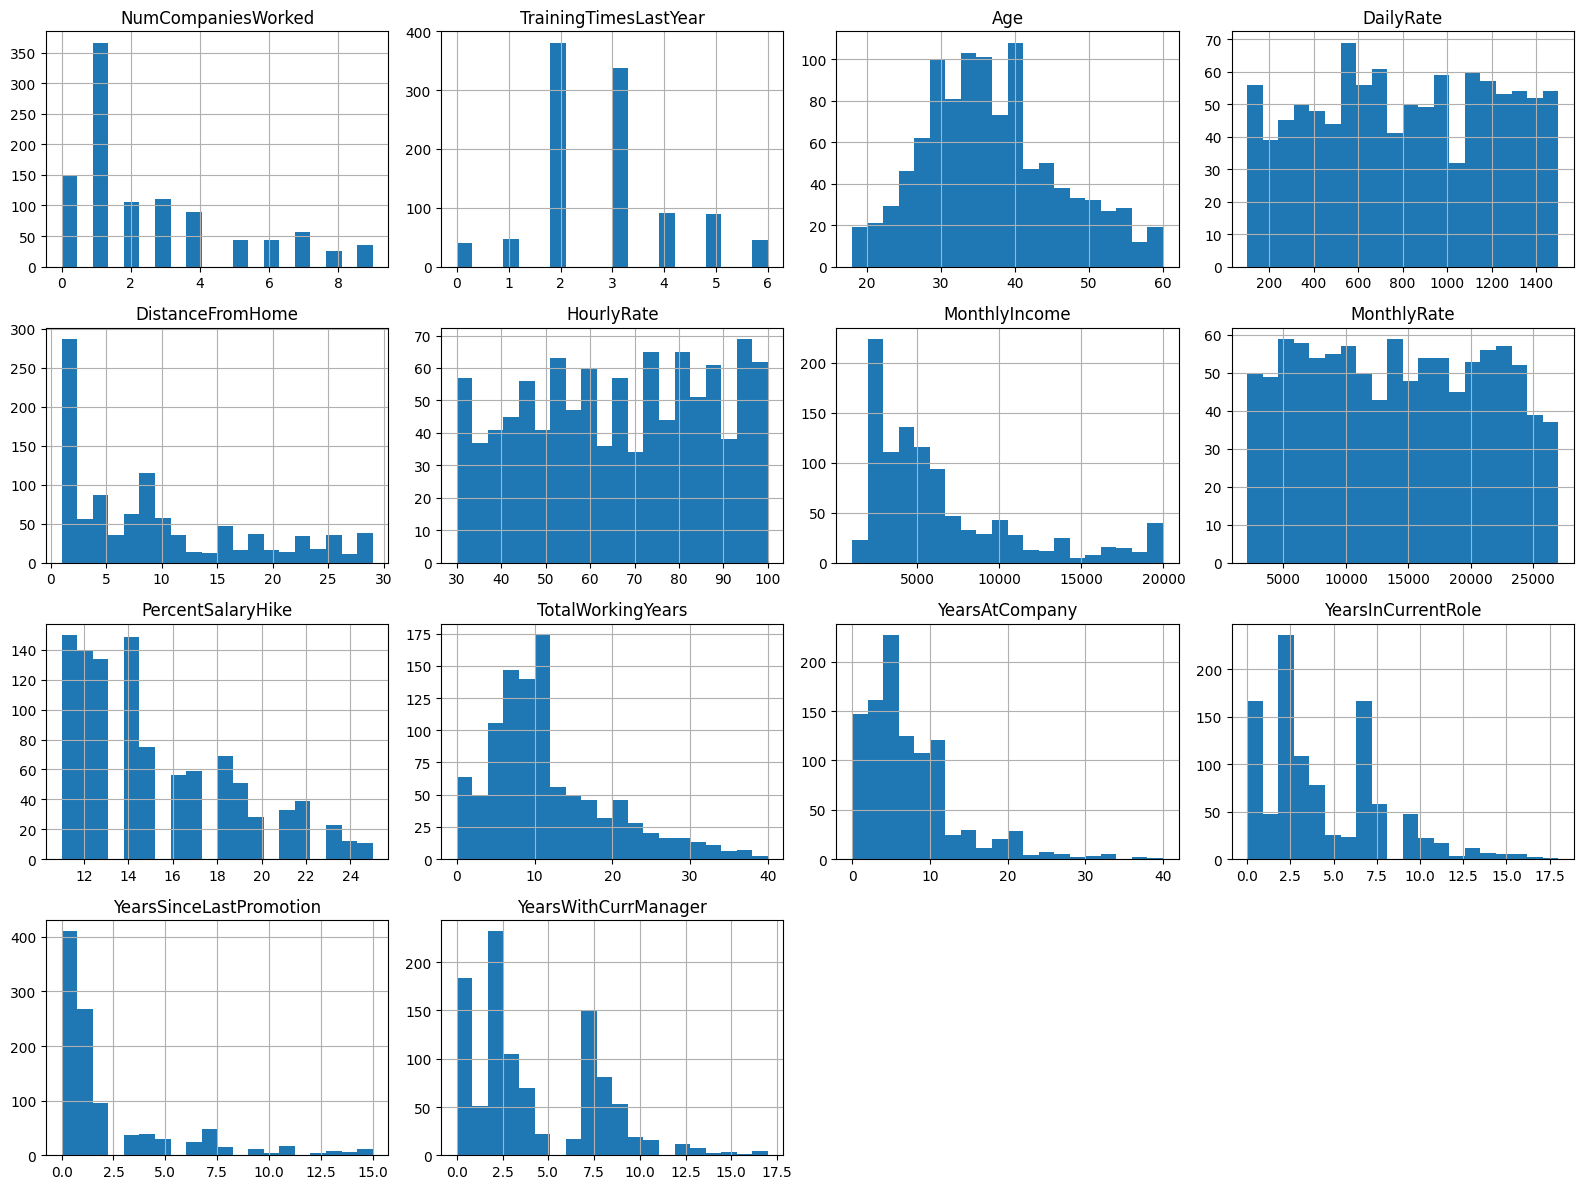

In [8]:

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# Incluye en esta sección todas las celdas que consideres necesarias.

# a) Análsis y gráficos

# a) Análisis y gráficos. Usamos solo Train para no tomar decisiones con datos de Val y Test.

train = Xtrain.join(ytrain)

numericas = ['NumCompaniesWorked', 'TrainingTimesLastYear', 'Age', 'DailyRate', 'DistanceFromHome',
             'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears',
             'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

print("Datos faltantes:", train.isna().sum().sum(), "\n")
print("Sesgo de las variables numéricas:")
print(train[numericas].skew().sort_values(ascending=False).round(2))

train[numericas].hist(bins=20, figsize=(16, 12))
plt.tight_layout()
plt.show()


a) Las 14 variables numéricas no tienen datos faltantes, pero la mayoría muestra una asimetría positiva: es decir que muchos empleados se concentran en valores bajos y unos pocos tienen valores muy altos, formando una cola larga a la derecha. Esto es más marcado en las variables de antigüedad, de ingresos y de número de empleos previos, y menos en las de distancia a casa y aumento salarial. Estas variables se beneficiarían de una transformación que reduzca el sesgo como Yeo-Johnson antes de escalarlas. Algunas variables de años en el puesto o con el jefe actual tienen dos picos, lo cual no se corrige con ninguna transformación, en este caso lo conveniente es solo tomarlo en cuenta. Por otro lado, la edad es casi simétrica y las tres tarifas (diaria, por hora y mensual) tienen una distribución plana y uniforme, por lo que solo necesitarían escalamiento y evaluar si es que aportan información relevante o no. Y por último, las variables de antigüedad pparecen estar muy correlacionadas entre sí, lo que podría generar multicolinealidad, y todas las transformaciones deben ajustarse únicamente con Train para evitar fuga de datos.

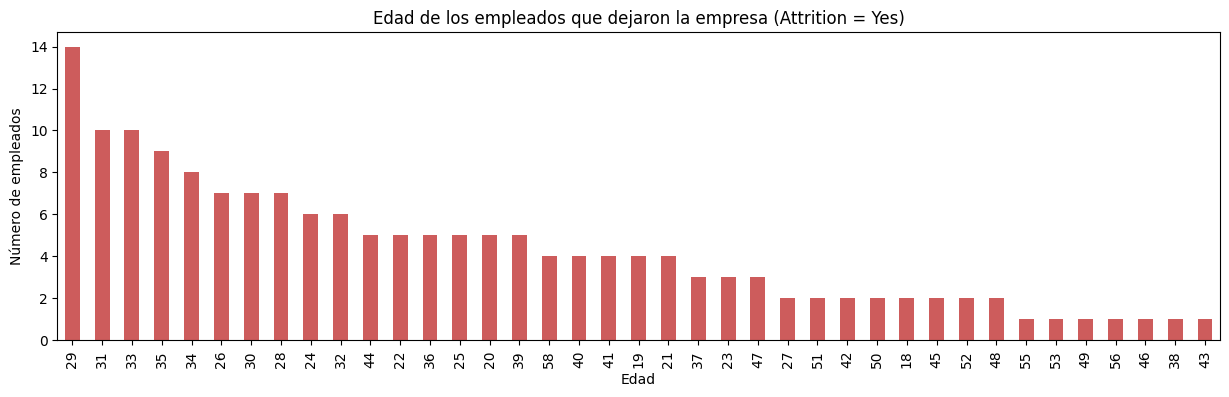

In [9]:
# b) Gráfico age-attrition[yes]

edad_yes = train.loc[train['Attrition'] == 'Yes', 'Age'].value_counts()   # value_counts ordena de mayor a menor

edad_yes.plot.bar(figsize=(15, 4), color='indianred')
plt.title('Edad de los empleados que dejaron la empresa (Attrition = Yes)')
plt.xlabel('Edad')
plt.ylabel('Número de empleados')
plt.show()

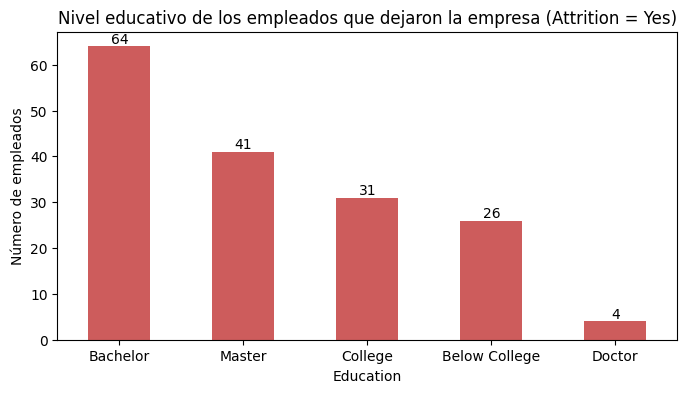

In [10]:
# c) Gráfico education-attrition[yes]

niveles_educacion = {1: 'Below College', 2: 'College', 3: 'Bachelor', 4: 'Master', 5: 'Doctor'}
educacion_yes = train.loc[train['Attrition'] == 'Yes', 'Education'].map(niveles_educacion).value_counts()

ax = educacion_yes.plot.bar(figsize=(8, 4), color='indianred', rot=0)
ax.bar_label(ax.containers[0])
plt.title('Nivel educativo de los empleados que dejaron la empresa (Attrition = Yes)')
plt.xlabel('Education')
plt.ylabel('Número de empleados')
plt.show()

**e) ¿Qué es más costoso, los Falsos Negativos o los Falsos Positivos?**

Es más costoso el falso negativo, es decir, predecir que un empleado se queda cuando en realidad se va. Esto se debe a que la empresa no se entera del riesgo y no actúa a tiempo, por lo que termina pagando la salida completa, lo cual involucra el reclutar, contratar, capacitar y perder productividad y experiencia.

# **Ejercicio 7:**

#### **Utiliza las clases Pipeline y ColumnTransformer de Sklearn para definir las transformaciones que deberás aplicar a cada variable y de acuerdo a su tipo considerado previamente.**



In [11]:
# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NUMÉRICAS:
numericas_pipeline = Pipeline(steps=[('imputar', SimpleImputer(strategy='median')),
                                     ('yeo_johnson', PowerTransformer())])
numericas_pipeline_nombres = ['NumCompaniesWorked', 'TrainingTimesLastYear', 'Age', 'DailyRate',
                              'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate',
                              'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
                              'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

# ORDINALES:
catOrd_pipeline = Pipeline(steps=[('imputar', SimpleImputer(strategy='most_frequent')),
                                  ('escalar', MinMaxScaler())])
catOrd_pipeline_nombres = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
                           'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
                           'StockOptionLevel', 'WorkLifeBalance']

# BINARIAS:
catBin_pipeline = Pipeline(steps=[('imputar', SimpleImputer(strategy='most_frequent')),
                                  ('onehot', OneHotEncoder(drop='if_binary'))])
catBin_pipeline_nombres = ['Gender', 'OverTime']

# NOMINALES:
catNom_pipeline = Pipeline(steps=[('imputar', SimpleImputer(strategy='most_frequent')),
                                  ('onehot', OneHotEncoder(handle_unknown='ignore'))])
catNom_pipeline_nombres = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']



columnasTransformer = ColumnTransformer(transformers=[('num', numericas_pipeline, numericas_pipeline_nombres),
                                                      ('ord', catOrd_pipeline, catOrd_pipeline_nombres),
                                                      ('bin', catBin_pipeline, catBin_pipeline_nombres),
                                                      ('nom', catNom_pipeline, catNom_pipeline_nombres)],
                                        verbose_feature_names_out=False)

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++

* #### **Vamos a utilizar validación cruzada, por lo que decidimos para esta actividad reagrupar los conjuntos de entrenamiento y validación en un solo DataFrame.**

* #### **Al resultado obtenido los llamaremos Xtv y ytv.**


In [12]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = pd.concat([ytrainT, yvalT], axis=0)


print("Dimensión del conjunto Train+Val:")
print(Xtv.shape)
print(ytv.shape)

Dimensión del conjunto Train+Val:
(1249, 30)
(1249, 1)


# **Ejercicio 8:**

#### **Entrenamiento y ajuste de hiperparámetros**

#### **a) Busca los mejores hiperparámetros para cada modelo, de manera que no estén subentrenados con respecto a la métrica de la exactitud (accuracy).**

#### **b) Incluye tus comentarios sobre el resultado obtenido.**



#### **NOTA-1: En dado caso, cuando mucho uno de los modelos podría quedar subentrenado.**

#### **NOTA-2: Por el momento estamos usando la métrica de la exactitud (accuracy). El objetivo de esta actividad es que sepas entrenar modelos sin que resulten subentrenados o sobreentrenados, independientemente de la métrica a considerar. En próximas semanas seguiremos con el estudio de las otras métricas para abordar de mejor manera los problemas y obtener mejores resultados.**

En relación a la variante de Validación Cruzada "RepeatedStratifiedKFold" utilizada en este ejercicio, puedes consultar la siguiente liga:

  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html


>> LR 0.885 (0.015)
>> LASSO 0.885 (0.013)
>> RIDGE 0.888 (0.013)
>> EN 0.887 (0.014)
>> KNN 0.852 (0.008)


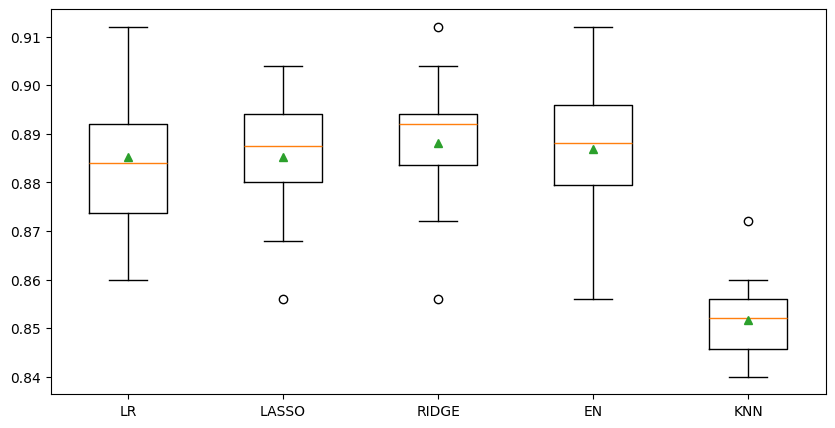

In [19]:
# 8a) Ajuste de hiperparámetros.
#     En cada modelo que utilcemos a continuación, utiliza la semilla "random_state=1"
#     indicada, para obtener la repetibilidad de los resultados en la manera de lo
#     posible. Es decir, este argumento y valor no deberás modificarlo.

def mis_modelos():
  modelos, nombres = list(), list()

  # LR
  modelos.append(LogisticRegression(penalty=None,
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')



  # Lasso
  modelos.append(LogisticRegression(penalty='l1',
                                    solver='liblinear', C=0.3,
                                    random_state=1))
  nombres.append('LASSO')



  # Ridge
  modelos.append(LogisticRegression(penalty='l2',
                                    C=0.3, max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')



  # Elastic_Net
  modelos.append(LogisticRegression(penalty='elasticnet',
                                    solver='saga', l1_ratio=0.5, C=0.3, max_iter=5000,
                                    random_state=1))
  nombres.append('EN')



  # KNN - K-Vecinos más cercanos:
  modelos.append(KNeighborsClassifier(n_neighbors=7, p=1
                                      ))
  nombres.append('KNN')

  return modelos, nombres


# Pasamos al entrenamiento de los modelos.
# Hay obviamente varias maneras de llevar a cabo el entrenamiento,
# pero por el momento supongamos que lo hacemos de la manera siguiente:

modelos, nombres = mis_modelos()  # accesando los modelos.
resultados = list()    # para guardar los resultados en esta lista.

# Iterando y entrenando sobre cada modelo:
for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])   # Conjuntamos Transformaciones y modelos en un Pipeline.

  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)     # Aplicando una de las variantes de Validación Cruzada.

  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring='accuracy', cv=cv1)   # Entrenando y generando los resultados con la exactitud (accuracy).


  resultados.append(scores)    # Guardamos los resultados en la lista.
  print('>> %s %.3f (%.3f)' % (nombres[i], np.nanmean(scores), np.nanstd(scores)))  # Desplegando los promedios de cada modelo.


plt.figure(figsize=(10,5))
plt.boxplot(resultados, tick_labels=nombres, showmeans=True)   # Gráficos de caja para una comparación visual de los resultados.
plt.show()

**8b) Comentarios sobre los resultados y modelos obtenidos. En particular indica cuál consideras el mejor modelo. ¿Alguno quedó subentrenado y ya no se pudo mejorar su desempeño?**

Los cuatro modelos lineales quedaron prácticamente empatados, con exactitud media entre 0.885 y 0.888 y cajas que se traslapan. Aun así, RIDGE tiene la media y la mediana más altas y una caja compacta, además de que su regularización ayuda con la multicolinealidad de las variables de antigüedad, por lo que podría decirse que es el mejor modelo. KNN quedó subentrenado: con 0.852 apenas superando el baseline de 0.8387, mientras que los lineales lo superan por alrededor de cinco puntos.


# **Ejercicio 9:**

* #### **Utiliza el mejor modelo encontrado en el paso anterior, los datos Xtv, ytv, y realiza ahora una búsqueda de malla con validación cruzada para tratar de mejorar el desempeño de este modelo.**

* #### **Sigue utilizando la métrica de la exactitud (accuracy).**

* #### **Verifica además que el modelo no esté subentrenado o sobreentrenado.**

* #### **Llama "resultado_malla" al mejor modelo ajustado.**




* **NOTA-1: Para esta actividad diremos que el modelo no está sobreentrenado si la diferencia entre Train y Validation es menor al 3%.**


* **NOTA-2: Puedes utilizar GridSearchCV, o bien, RandomizedSearchCV. La documentación la puedes consultar en las siguientes ligas:**

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html


In [20]:
# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++

pipeline_malla = Pipeline(steps=[('ct', columnasTransformer),
                                 ('m', LogisticRegression(penalty='l2', max_iter=2000, random_state=1))])

malla = {'m__C': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 2],
         'm__solver': ['lbfgs', 'liblinear']}

cv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

resultado_malla = GridSearchCV(pipeline_malla, malla, scoring='accuracy', cv=cv2,
                               return_train_score=True, n_jobs=-1).fit(Xtv, np.ravel(ytv))


print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Promedios Train mean(std): %.2f%% (%.4f%%)' % (100*np.nanmean(resultado_malla.cv_results_['mean_train_score']),
                                                 100*np.nanmean(resultado_malla.cv_results_['std_train_score'])))
print('Promedios Val mean(std): %.2f%% (%.4f%%)' % (100*resultado_malla.cv_results_['mean_test_score'].mean(),
                                               100*resultado_malla.cv_results_['std_test_score'].mean()))

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Promedios Train mean(std): %.2f%% (%.4f%%)' % (100*np.nanmean(resultado_malla.cv_results_['mean_train_score']),
                                                 100*np.nanmean(resultado_malla.cv_results_['std_train_score'])))
print('Promedios Val mean(std): %.2f%% (%.4f%%)' % (100*resultado_malla.cv_results_['mean_test_score'].mean(),
                                               100*resultado_malla.cv_results_['std_test_score'].mean()))


Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.888978 usando los hiperparámetros {'m__C': 0.4, 'm__solver': 'liblinear'}
Promedios Train mean(std): 89.93% (0.4777%)
Promedios Val mean(std): 88.39% (1.3819%)
Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.888978 usando los hiperparámetros {'m__C': 0.4, 'm__solver': 'liblinear'}
Promedios Train mean(std): 89.93% (0.4777%)
Promedios Val mean(std): 88.39% (1.3819%)


# **Ejercicio 10:**

#### **Finalmente, usando el conjunto de prueba (Test) responde los siguientes incisos:**

#### **a) Obtener el desempeño final del mejor modelo con el reporte de métricas classification_report() de Sklearn.**

#### **b) Obtener la matriz de confusión del mejor modelo.**

#### **c) Indica como se leen o interpretan los valores VP, VN, FP, FN obtenidos y de acuerdo al contexto del problema.**

#### **d) Realiza un análisis de importancia de los factores o características e incluye tus comentarios.**



In [22]:
# a) Reporte del desempeño con classification_report():

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++

# a) Reporte del desempeño con classification_report():

ypred = resultado_malla.predict(Xtest)

print(classification_report(np.ravel(ytestT), ypred,
                            target_names=['No','Yes']))

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


              precision    recall  f1-score   support

          No       0.89      0.96      0.92       185
         Yes       0.65      0.36      0.46        36

    accuracy                           0.86       221
   macro avg       0.77      0.66      0.69       221
weighted avg       0.85      0.86      0.85       221



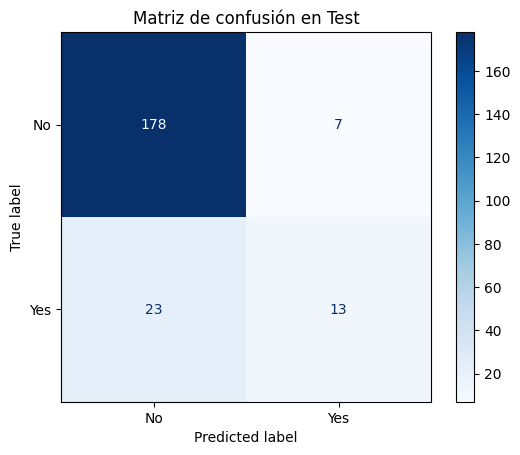

In [23]:
# b) Matriz de confusión:

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++
ConfusionMatrixDisplay.from_predictions(np.ravel(ytestT), ypred, display_labels=['No', 'Yes'], cmap='Blues')
plt.title('Matriz de confusión en Test')
plt.show()

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


*  c) Interpretación de VP, VF, FP, FN.
#### +++++++++ Inicia sección para incluir tus comentarios ++++++++++++++++++++++++

None


* **VP:** 13

* **VN:** 178

* **FP:** 7

* **FN:** 23

El modelo acierta mucho con quienes se quedan, pero solo detecta 13 de los 36 que realmente se van y los falsos negativos, con 23, son el error más frecuente y más costoso.


#### +++++++++ Termina sección para incluir tus comentarios ++++++++++++++++++++++++

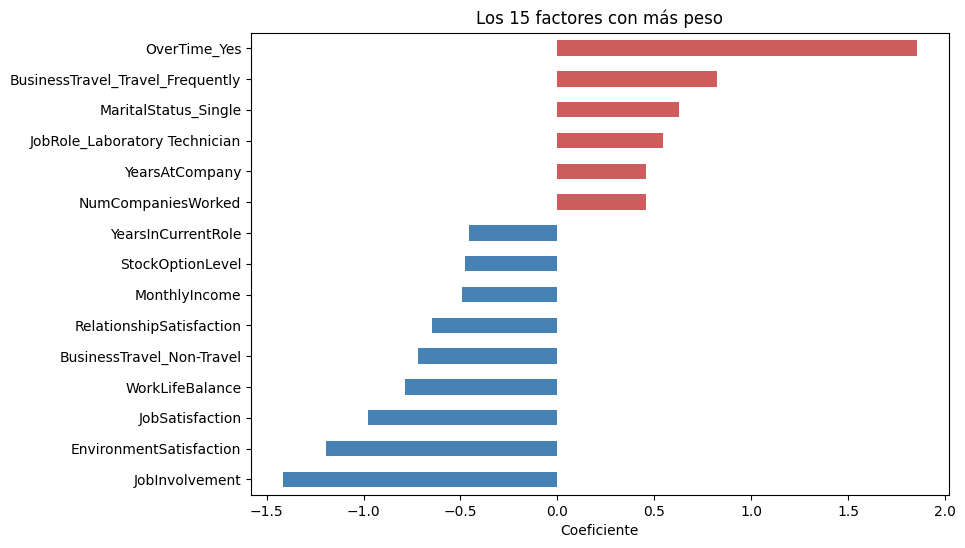

In [24]:
# 10d) Inportancia de factores

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++

modelo = resultado_malla.best_estimator_
coeficientes = pd.Series(modelo.named_steps['m'].coef_[0],
                         index=modelo.named_steps['ct'].get_feature_names_out())

top = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(15).sort_values()

top.plot.barh(figsize=(9, 6), color=np.where(top > 0, 'indianred', 'steelblue'))
plt.title('Los 15 factores con más peso')
plt.xlabel('Coeficiente')
plt.show()

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++



*  **10d) Comentarios sobre los resultados sobre el análisis de importancia de factores o características**


De acuerdo a los resultados, el mayor riesgo de renuncia se asocia con las horas extra, siendo este el factor más fuerte, tambien con los viajes frecuentes, ser soltero y haber tenido muchos empleos anteriormente, mientras que el involucramiento, la satisfacción con el puesto y el ambiente, el equilibrio vida-trabajo y un mayor ingreso se asocian con quedarse. Como la mayoría de estos factores son accionables, la empresa podría ser capaz de intervenir y no solo predecir.


# **Ejercicio 11:**


### **Para terminar, responde las siguientes preguntas relacionadas con las implicaciones involucradas con la toma de decisiones basadas en los resultados de un modelo de aprendizaje automático. El objetivo es reflexionar sobre estas implicaciones y no dudes en compartir tus experiencias en caso de que te hayas enfrentado a una situación similar en tu trabajo.**

* **a) Si tu modelo predice e identifica con un alto porcentaje de exactitud quiénes de los colaboradores de la empresa estarán abandonando su puesto muy pronto, ¿cómo debería usarse esa información? Al responder, considera que es importante cuidar la parte ética y de privacidad de la información del colaborador.**

* **b) Con base a los resultados de la matriz de confusión, ¿qué tipo de error (FN o FP) está considerando como más costoso el modelo? En particular, ¿coincide con la respuesta que diste en el Ejercicio 6e?**

* **c) ¿Cómo comunicarías los resultados del modelo obtenido en esta actividad a un público no técnico, es decir, sin los conocimientos de temas de aprendizaje automático. Por ejemplo, supongamos que vas a comunicarle tus resultados a los directivos de la empresa o al personal del área de Recursos Humanos.**

* **d) ¿En cuáles ejercicios anteriores consideras que el (o los) modelo de lenguaje de gran tamaño LLM utilizado fue de mayor ayuda? ¿Por qué?**

* **e) Incluye tus conclusiones finales de la actividad.**

---


* a) Las predicciones deberían utilizarse para apoyar a los empleados con planes de retención, ajustes de carga, planes de desarrollo, y no para castigar ni decidir de forma automática. También es importante proteger la privacidad de cada persona, dando solamente acceso limitado a personal de recursos humanos, teniendo un aviso de privacidad, y no utilizar variables como la edad, género ni estado civil.
* b) El modelo tolera más los FN (23) que los FP (7), con recall ≈ 36%. No coincide con el 6e, donde dije que el FN es el más costoso.
* c) Se encontró que las horas extra, los viajes frecuentes y la baja satisfacción se asocian con más renuncias. El modelo acierta cerca del 86%, pero solo detecta a 1 de cada 3 que se van, así que esto es solo una guía y no una predicción definitiva. Se debe utilizar para mejorar condiciones de trabajo y no para juzgar a personas de acuerdo a sesgos.
* d) Fue de más ayuda en la interpretación el análisis descriptivo y transformaciones, matriz de confusión, importancia de factores y aspectos éticos, porque explica y sintetiza las ideas de forma rápida y clara.
* e) La exactitud, que es del 86%, muy apenas supera el baseline de 84% y es engañoso con clases desbalanceadas, por lo que hay que considerar utilizar otras alternativas como recall y F1. Los factores clave como las horas extra, viajes y satisfacción son accionables, así que el modelo sirve para realizar diagnosticos, siempre con ética, privacidad y análisis, no se debe tomar la ifnromación ciegamente.


# >> **Fin de la Actividad de Rotación de Personal de la Semana 3** <<